# Build the Model

Forecast hourly BPA demand from weather and the calendar, and compare it with EIA's day-ahead forecast.

**What this notebook does:**
1. **Features (Steps 1–3):** builds `features_hourly` in SQL (calendar, holidays, growth trend, weather per location, degree-hours, rolling temperatures) and splits it by time: train 2021–2023, validate 2024, test Jan 2025 – Aug 2026.
2. **Baselines (Step 4):** same hour last week, and linear regression.
3. **Gradient boosting (Step 5):** tuned on 2024, then diagnosed: trees can't extrapolate the growth trend, so the trend is removed before training (weather-adjusted trend from the linear model).
4. **Test period (Step 6):** retrained on 2021–2024 and scored once on the test period against EIA, with error breakdowns, feature importance and saved predictions.


## Setup

In [57]:
import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pandas.tseries.holiday import USFederalHolidayCalendar

#new scikit-learn 
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, root_mean_squared_error
from sklearn.inspection import permutation_importance


Imports for the whole notebook, including the scikit-learn pieces:
- `HistGradientBoostingRegressor`: scikit-learns gradient boosting
- `LinearRegression`: a simple baseline to compare against
- `mean_absolute_error`, `mean_absolute_percentage_error`, `root_mean_squared_error`: MAE / MAPE / RMSE used before
- `permutation_importance`: which features the model relies on most

In [58]:
#connect to the data
con = duckdb.connect("../data/grid.duckdb")
con.sql("SET TimeZone = 'UTC'")

con.sql("SHOW TABLES")

┌─────────────────┐
│      name       │
│     varchar     │
├─────────────────┤
│ demand_clean    │
│ demand_issues   │
│ demand_wide     │
│ eia_raw         │
│ features_hourly │
│ major_holidays  │
│ model_hourly    │
│ weather_raw     │
│ weather_wide    │
└─────────────────┘

See all the tables from before and the model_hourly made

## Features

Here are the features explored in EDA

| Finding | Features |
|---|---|
| Daily shape differs by season | `hour_pacific`, `month` |
| Weekends demand is lower | `day_of_week`, `is_weekend` |
| Major holidays demand is lower | `is_major_holiday` |
| Demand growing  | `years_since_start` |
| V-shaped temperature response, balance point ~60 | temperature, heating and cooling degree-hours, per location |
| Demand reacts to the last 12–24 hours of weather | rolling 12 h and 24 h temperature, per location |

Plus the other weather variables (humidity, wind, cloud, solar) for the model to use or ignore.

**NOTE** `eia_forecast_mwh` is not a feature but is kept in the table only to score against, since feeding EIA's forecast in would be cheating on the comparison.

## Step 1 -> Major holidays table

In [59]:
#the holidays that consistently cut demand 
#the major holidays seen in EDA
MAJOR = ["New Year's Day", "Independence Day", "Thanksgiving Day", "Christmas Day"]

#observed dates if it is observed on the day before or after 
cal = USFederalHolidayCalendar().holidays(start="2021-01-01", end="2026-12-31", return_name=True)
observed = pd.DataFrame({"date": cal.index.date, "holiday": cal.values})
observed = observed[observed["holiday"].isin(MAJOR)] #add ones matching list above

#the actual dates too
actual = pd.DataFrame(
    [(pd.Timestamp(year, m, d).date(), name) #format time
     for year in range(2021, 2027) #
     for (m, d, name) in [(1, 1, "New Year's Day"), (7, 4, "Independence Day"), (12, 25, "Christmas Day")]],
    columns=["date", "holiday"],
)
#no thanksgiving- date changes but always is on a thursday 
print(f"Difference between Observed and Actual: {len(observed) - len(actual)}")
holidays_df = pd.concat([observed, actual]).drop_duplicates("date").sort_values("date")


Difference between Observed and Actual: 6


In [60]:
#now need to put these into data table
#use .register() in duckdb to add or 'register' this table
con.register("holidays_df", holidays_df)

#now make it
con.sql("""
    CREATE OR REPLACE TABLE major_holidays AS
    SELECT date, holiday
    FROM holidays_df
""")

#quick check
con.sql("SELECT * FROM major_holidays").show(max_rows=40)

┌────────────┬──────────────────┐
│    date    │     holiday      │
│    date    │     varchar      │
├────────────┼──────────────────┤
│ 2021-01-01 │ New Year's Day   │
│ 2021-07-04 │ Independence Day │
│ 2021-07-05 │ Independence Day │
│ 2021-11-25 │ Thanksgiving Day │
│ 2021-12-24 │ Christmas Day    │
│ 2021-12-25 │ Christmas Day    │
│ 2021-12-31 │ New Year's Day   │
│ 2022-01-01 │ New Year's Day   │
│ 2022-07-04 │ Independence Day │
│ 2022-11-24 │ Thanksgiving Day │
│ 2022-12-25 │ Christmas Day    │
│ 2022-12-26 │ Christmas Day    │
│ 2023-01-01 │ New Year's Day   │
│ 2023-01-02 │ New Year's Day   │
│ 2023-07-04 │ Independence Day │
│ 2023-11-23 │ Thanksgiving Day │
│ 2023-12-25 │ Christmas Day    │
│ 2024-01-01 │ New Year's Day   │
│ 2024-07-04 │ Independence Day │
│ 2024-11-28 │ Thanksgiving Day │
│ 2024-12-25 │ Christmas Day    │
│ 2025-01-01 │ New Year's Day   │
│ 2025-07-04 │ Independence Day │
│ 2025-11-27 │ Thanksgiving Day │
│ 2025-12-25 │ Christmas Day    │
│ 2026-01-01 │

How it is working:
- `return_name=True` makes pandas return each holiday's name with its date, so the list can be filtered to the four major ones.
- **Observed vs actual dates:** when a holiday falls on a weekend, the federal *observed* day moves to the nearest weekday and demand drops on both days, so both get flagged. Thanksgiving is always a Thursday, so it only needs the observed list.
- `.drop_duplicates("date")` removes the overlap when the observed and actual dates are the same day.
- `con.register("holidays_df", holidays_df)` lets DuckDB query a pandas DataFrame by name, then `CREATE TABLE ... AS SELECT` saves it into the database so SQL can join to it. This is the reverse of `.df()`, going pandas → DuckDB.

## Step 2 -> Build `features_hourly`

In [61]:
#making a new table say create it then build columns it wants

con.sql("""
    CREATE OR REPLACE TABLE features_hourly AS --create it

    WITH base AS ( --CTE to get the pacific time conversion 
        SELECT
            *,
            period_utc AT TIME ZONE 'America/Los_Angeles' AS period_pacific
        FROM model_hourly
    )

    SELECT --big statement here to make the columns we are choosing for the table
        b.period_utc, --using CTE with period_utc as connecting key

        --target and benchmark from table
        b.demand_mwh,
        b.eia_forecast_mwh,

        --which part of the data each hour belongs to
        CASE
            WHEN YEAR(b.period_pacific) <= 2023 THEN 'train' --basically if/else statements
            WHEN YEAR(b.period_pacific) = 2024  THEN 'valid'
            ELSE 'test'
        END AS split, --naming split for later

        --calendar features
        HOUR(b.period_pacific) AS hour_pacific, --gets hour value between 0-23
        ISODOW(b.period_pacific) AS day_of_week, --gets day of week 1-7
        MONTH(b.period_pacific) AS month, --gets month 1-12
        CAST(ISODOW(b.period_pacific) >= 6 AS INTEGER) AS is_weekend, --check weekend then turn T/F to 1/0 for sckit
        CAST(h.date IS NOT NULL AS INTEGER) AS is_major_holiday, --check if there is value if yes 1 otherwise 0

        --trend years since the start of the data
        --DATE_DIFF() counts hours between two timestamps so give it predefined and then new period ones we are using
        DATE_DIFF('hour', TIMESTAMPTZ '2021-01-01 00:00:00+00', b.period_utc) / 8766.0 AS years_since_start, 

        --temperature per location
        b.eugene_temp_f,
        b.everett_temp_f,
        b.kennewick_temp_f,
        b.vancouver_wash_temp_f,

        --heating degree-hours 60 as pivot, temp below 60
        GREATEST(60 - b.eugene_temp_f, 0) AS eugene_hdh, --greatest returns larger of the given arguments
        GREATEST(60 - b.everett_temp_f, 0) AS everett_hdh,
        GREATEST(60 - b.kennewick_temp_f, 0) AS kennewick_hdh,
        GREATEST(60 - b.vancouver_wash_temp_f, 0) AS vancouver_wash_hdh,

        --cooling degree-hours, temp above 60
        GREATEST(b.eugene_temp_f - 60, 0) AS eugene_cdh,
        GREATEST(b.everett_temp_f - 60, 0) AS everett_cdh,
        GREATEST(b.kennewick_temp_f - 60, 0) AS kennewick_cdh,
        GREATEST(b.vancouver_wash_temp_f - 60, 0) AS vancouver_wash_cdh,

        --recent weather for rolling average temperature over the last 12 and 24 hours
        AVG(b.eugene_temp_f) OVER last_12h AS eugene_temp_roll12_f, --OVERS are done on defined WINDOWS below
        AVG(b.everett_temp_f) OVER last_12h AS everett_temp_roll12_f,
        AVG(b.kennewick_temp_f) OVER last_12h AS kennewick_temp_roll12_f,
        AVG(b.vancouver_wash_temp_f) OVER last_12h AS vancouver_wash_temp_roll12_f,

        AVG(b.eugene_temp_f) OVER last_24h AS eugene_temp_roll24_f,
        AVG(b.everett_temp_f) OVER last_24h AS everett_temp_roll24_f,
        AVG(b.kennewick_temp_f) OVER last_24h AS kennewick_temp_roll24_f,
        AVG(b.vancouver_wash_temp_f) OVER last_24h AS vancouver_wash_temp_roll24_f,

        --other weather per location pull from table get each variable at each location
        b.eugene_humidity_pct, b.everett_humidity_pct, b.kennewick_humidity_pct, b.vancouver_wash_humidity_pct,
        b.eugene_wind_mph, b.everett_wind_mph, b.kennewick_wind_mph, b.vancouver_wash_wind_mph,
        b.eugene_cloud_pct, b.everett_cloud_pct, b.kennewick_cloud_pct, b.vancouver_wash_cloud_pct,
        b.eugene_solar_wm2, b.everett_solar_wm2, b.kennewick_solar_wm2, b.vancouver_wash_solar_wm2

    FROM base AS b --naming to use above and where data is being pulled 
    LEFT JOIN major_holidays AS h --other table name 
        ON CAST(b.period_pacific AS DATE) = h.date

    WINDOW
        last_12h AS (ORDER BY b.period_utc ROWS BETWEEN 11 PRECEDING AND CURRENT ROW), --order by to define correct window
        last_24h AS (ORDER BY b.period_utc ROWS BETWEEN 23 PRECEDING AND CURRENT ROW)

    ORDER BY b.period_utc --order by the period at the end
""")

How it is working big one that took some time to put together:
- **`split`:** labels each hour as train (2021–2023), valid (2024) or test (Jan 2025 – Aug 2026), using Pacific years. Putting it in the table means every later step uses exactly the same split and easy to call from
- **`CAST(... AS INTEGER)`** turns TRUE/FALSE into 1/0, which is what the model expects.
- **`years_since_start`:** hours since the first hour divided by 8,766 ( hours in a year given by 365.25 × 24), so 2.5 means two and a half years in which is done so the model can see growth over time.
- **`GREATEST(60 - temp, 0)`** this is clipping the data using SQL so it is how far below 60 or 0
- **`WINDOW last_12h AS (...)`** defines a named window to use. So each rolling column can say `OVER last_12h` instead of repeating the full definition eight times. `ROWS BETWEEN 11 PRECEDING AND CURRENT ROW` covers the current hour plus the 11 before it, which is 12 hours. At the very start of the data the window is shorter until we get enought data to make the full 12 which should only impact the first data
- **Rolling windows are computed on every hour**, That's why this is built from `model_hourly` with no filtering so we don't skip days

personal note -used LLm to help get this all right

In [62]:
#checks: rows per split, and how many have a demand value to train or score on
con.sql("""
    SELECT
        split, --now can call split
        COUNT(*) AS n_hours,
        COUNT(demand_mwh) AS n_with_demand,
        MIN(period_utc) AS first_hour,
        MAX(period_utc) AS last_hour
    FROM features_hourly
    GROUP BY split
    ORDER BY first_hour
""")

┌─────────┬─────────┬───────────────┬──────────────────────────┬──────────────────────────┐
│  split  │ n_hours │ n_with_demand │        first_hour        │        last_hour         │
│ varchar │  int64  │     int64     │ timestamp with time zone │ timestamp with time zone │
├─────────┼─────────┼───────────────┼──────────────────────────┼──────────────────────────┤
│ train   │   26288 │         26240 │ 2021-01-01 00:00:00+00   │ 2024-01-01 07:00:00+00   │
│ valid   │    8784 │          8784 │ 2024-01-01 08:00:00+00   │ 2025-01-01 07:00:00+00   │
│ test    │   14584 │         14584 │ 2025-01-01 08:00:00+00   │ 2026-08-31 23:00:00+00   │
└─────────┴─────────┴───────────────┴──────────────────────────┴──────────────────────────┘

Got the expected counts:
- **train:** 26,288 hours, 26,240 with demand (the 48 dropped hours are both in 2021 and 2023). It also includes the 8 hours that are Dec 31, 2020 in Pacific time.
- **valid:** 8,784 hours (2024 was a leap year: 366 × 24).
- **test:** 14,584 hours.
- Total 49,656, which matches `model_hourly`.

The splits start at 08:00 UTC because that's midnight Pacific (standard time) on Jan 1.

In [63]:
#no feature should have missing values
#only demand_mwh (48) and eia_forecast_mwh (72) can 
con.sql("SUMMARIZE features_hourly").df()[["column_name", "column_type", "min", "max", "null_percentage"]]

,column_name,column_type,min,max,null_percentage
0,period_utc,TIMESTAMP WITH TIME ZONE,2021-01-01 00:00:00+00,2026-08-31 23:00:00+00,0.00
1,demand_mwh,DOUBLE,3804.0,11537.0,0.10
2,eia_forecast_mwh,DOUBLE,4226.0,11668.0,0.14
3,split,VARCHAR,test,valid,0.00
4,hour_pacific,BIGINT,0,23,0.00
5,day_of_week,BIGINT,1,7,0.00
6,month,BIGINT,1,12,0.00
7,is_weekend,INTEGER,0,1,0.00
8,is_major_holiday,INTEGER,0,1,0.00
9,years_since_start,DOUBLE,0.0,5.664499201460187,0.00


In [64]:
#holiday flag check: how many holiday days fall inside the data?
con.sql("""
    SELECT SUM(is_major_holiday) / 24 AS holiday_days
    FROM features_hourly
""")

┌──────────────┐
│ holiday_days │
│    double    │
├──────────────┤
│         28.0 │
└──────────────┘

28 days, a quick count for the major holidays gives a match, 6 X 4 = 24 then -2 (for Thanksgiving/Christmas for 2026) gives 22. Checking the difference between observed and actual gives 6 different counts to get 22+6= 28.Every holiday day contributes 24 flagged hours

## Step 3 -> Load into pandas and set up the model inputs

scikit-learn works on pandas/NumPy, so the features come out of DuckDB once here. Following the plan:
- **`X`** = feature columns (the model inputs), **`y`** = `demand_mwh` (what it predicts)
- Rows with no demand (the two dropped days) are removed, since there's nothing to learn from or score against.

In [65]:
#pull the features from the table made and turn into dataframe
feat = con.sql("SELECT * FROM features_hourly WHERE demand_mwh IS NOT NULL ORDER BY period_utc").df()

#everything except identifiers, the target, the benchmark and the split label
NOT_FEATURES = ["period_utc", "demand_mwh", "eia_forecast_mwh", "split"] #remove things that shouldn't be features from the datatable
FEATURES = [c for c in feat.columns if c not in NOT_FEATURES]

#create the split data
train = feat[feat["split"] == "train"]
valid = feat[feat["split"] == "valid"]
test  = feat[feat["split"] == "test"]

#X = Features and Y = demand for each data split above
X_train, y_train = train[FEATURES], train["demand_mwh"]
X_valid, y_valid = valid[FEATURES], valid["demand_mwh"]
X_test,  y_test  = test[FEATURES],  test["demand_mwh"]

print(len(FEATURES), "features")
print("train:", X_train.shape, " valid:", X_valid.shape, " test:", X_test.shape) 

42 features
train: (26240, 42)  valid: (8784, 42)  test: (14584, 42)


Got **42 features**, and train / valid / test shapes of (26240, 42), (8784, 42) and (14584, 42), which matches the split counts above.

- `FEATURES` is built by *excluding* columns rather than listing them, so any feature added to the SQL later is picked up automatically, while the target and benchmark can never slip in by accident.
- `test` is set aside now and **not touched** until the final evaluation. All tuning and comparisons happen on `valid`. If the test set guides any decisions, its score stops being an honest estimate of real-world performance.

## Step 4 -> Baselines
Create some baselines to compare to 
1. **Same hour last week**: no model at all, just copy demand from 7 days earlier.
2. **Linear regression** on the same features.

Gradient boosting should beat these and if it doesn't then: 
1. something went wrong
2. we should use the simpler model

Okay as we build we need to be able to check how it is doing. So make a function to compare the results based on error/bias as we did before

In [66]:
def comparison(y_true,y_pred, name):
    """
    MAE, MAPE, RMSE, and BIAS for set of predictions use scikit learn
    """

    score = pd.DataFrame({
        "model": [name],
        "mae_mwh": [mean_absolute_error(y_true,y_pred)],
        "mape_pct": [100*mean_absolute_percentage_error(y_true,y_pred)],
        "rmse_mwh": [root_mean_squared_error(y_true,y_pred)],
        "bias_mwh": [ np.mean(y_pred-y_true)],
    }).round(2)
    return score

In [67]:
#pull data to look at for baseline 1 which is just comparing last week
last_week = con.sql("""
    SELECT 
        period_utc,
        LAG(demand_mwh, 168) OVER (ORDER BY period_utc) AS demand_last_week --168 is 7 days
    FROM features_hourly --need to start on the train not valid so first week of valid will require last week of train
    ORDER BY period_utc
""").df() 

In [68]:
#now add this to what we should validate for checking
valid = valid.merge(last_week,on="period_utc", how='left')
print("Missing last week data values in valid:", valid["demand_last_week"].isna().sum())

results = [comparison(valid["demand_mwh"], valid["demand_last_week"], "Same Hour last week")]
results[0]

Missing last week data values in valid: 0


,model,mae_mwh,mape_pct,rmse_mwh,bias_mwh
0,Same Hour last week,479.06,6.85,672.65,-7.26


How this works:
- **last_week**: is data made from the last week of data. It comes from the features so I can pull the first week from train and then move forward
- Make table with merge that adds the data to valid and then run comparison on the new data to see how each works
- slight underforcast with bias and ~7% MAPE

In [69]:
#second baseline is using linear regression
#setup
CATEGORY = ["hour_pacific", "day_of_week", "month"]

X_train_line = pd.get_dummies(X_train, columns=CATEGORY, drop_first=True, dtype=int)
X_valid_line = pd.get_dummies(X_valid, columns=CATEGORY, drop_first=True, dtype=int)
X_valid_line = X_valid_line.reindex(columns=X_train_line.columns, fill_value=0) #match train data

print(X_train_line.shape, X_valid_line.shape)

(26240, 79) (8784, 79)


In [70]:
#now use linear regression
lin = LinearRegression()
lin.fit(X_train_line, y_train)

valid["predict_linear"] = lin.predict(X_valid_line)

#add to results
results.append(comparison(valid["demand_mwh"], valid["predict_linear"],"Linear Regression"))
results[-1]

,model,mae_mwh,mape_pct,rmse_mwh,bias_mwh
0,Linear Regression,218.59,3.28,277.93,-59.8


This does better than last week in terms of error but a larger under bias appears. 
Note that we uses drop_first and dummies. LR using every input as an amount and in terms of time the 8th hour values isn't 8 times hour 1 since hours/days/months are labels. 
- The pd.get_dummies() turns the label column into 0/1 columns with oner per value so we can learn an adjustment for each hour
- drop_first=True drops one column per group becoming the baseline for other to compare against and stops duplication


In [71]:
#now use EIA on same validation hours
has_eia = valid["eia_forecast_mwh"].notna()
results.append(comparison(valid.loc[has_eia,"demand_mwh"], valid.loc[has_eia, "eia_forecast_mwh"], "EIA day-ahead 'Benchmark'")) #probably should have done this first

scores = pd.concat(results, ignore_index=True)
display(scores)

,model,mae_mwh,mape_pct,rmse_mwh,bias_mwh
0,Same Hour last week,479.06,6.85,672.65,-7.26
1,Linear Regression,218.59,3.28,277.93,-59.80
2,EIA day-ahead 'Benchmark',134.68,1.97,178.53,-18.27


Have a comparison table present and the EIA forecast obviously does the best. 

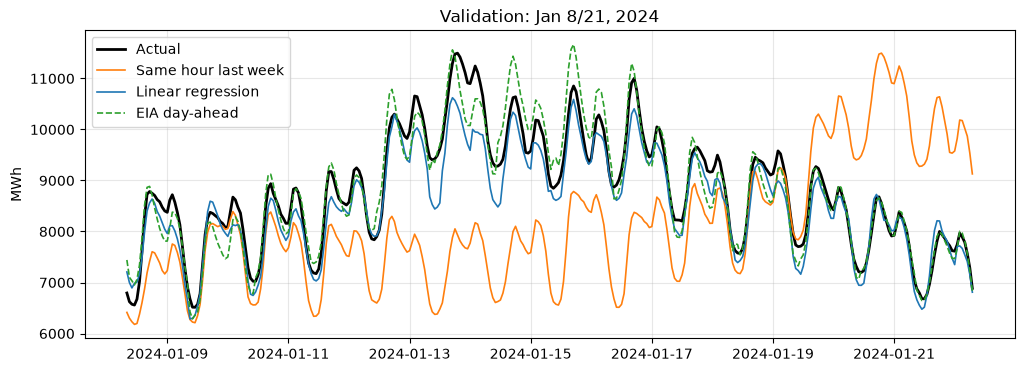

In [72]:
week = valid[(valid["period_utc"] >= "2024-01-08 08:00:00+00") & (valid["period_utc"] < "2024-01-22 08:00:00+00")]

fig, ax = plt.subplots(figsize=(12, 4))

#plots on the axes
ax.plot(week["period_utc"], week["demand_mwh"], color="black", linewidth=2, label="Actual")
ax.plot(week["period_utc"], week["demand_last_week"], color='C1', linewidth=1.2, label="Same hour last week")
ax.plot(week["period_utc"], week["predict_linear"], color="C0", linewidth=1.2, label="Linear regression")
ax.plot(week["period_utc"], week["eia_forecast_mwh"], color="C2", linewidth=1.2, linestyle="--", label="EIA day-ahead")

ax.set_ylabel("MWh")
ax.set_title("Validation: Jan 8/21, 2024")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

## Step 5 -> Gradient boosting

In [73]:
#move to gradient boosting
gbm_default = HistGradientBoostingRegressor(random_state=42)
gbm_default.fit(X_train,y_train)

,"random_state random_state: int, RandomState instance or None, default=NonePseudo-random number generator to control the subsampling in thebinning process, and the train/validation data split if early stoppingis enabled.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'squared_error', 'absolute_error', 'gamma', 'poisson', 'quantile'}, default='squared_error'The loss function to use in the boosting process. Note that the""squared error"", ""gamma"" and ""poisson"" losses actually implement""half least squares loss"", ""half gamma deviance"" and ""half poissondeviance"" to simplify the computation of the gradient. Furthermore,""gamma"" and ""poisson"" losses internally use a log-link, ""gamma""requires ``y > 0`` and ""poisson"" requires ``y >= 0``.""quantile"" uses the pinball loss... versionchanged:: 0.23 Added option 'poisson'... versionchanged:: 1.1 Added option 'quantile'... versionchanged:: 1.3 Added option 'gamma'.",'squared_error'
,"quantile quantile: float, default=NoneIf loss is ""quantile"", this parameter specifies which quantile to be estimatedand must be between 0 and 1.",None
,"learning_rate learning_rate: float, default=0.1The learning rate, also known as *shrinkage*. This is used as amultiplicative factor for the leaves values. Use ``1`` for noshrinkage.",0.1
,"max_iter max_iter: int, default=100The maximum number of iterations of the boosting process, i.e. themaximum number of trees.",100
,"max_leaf_nodes max_leaf_nodes: int or None, default=31The maximum number of leaves for each tree. Must be strictly greaterthan 1. If None, there is no maximum limit.",31
,"max_depth max_depth: int or None, default=NoneThe maximum depth of each tree. The depth of a tree is the number ofedges to go from the root to the deepest leaf.Depth isn't constrained by default.",None
,"min_samples_leaf min_samples_leaf: int, default=20The minimum number of samples per leaf. For small datasets with lessthan a few hundred samples, it is recommended to lower this valuesince only very shallow trees would be built.",20
,"l2_regularization l2_regularization: float, default=0The L2 regularization parameter penalizing leaves with small hessians.Use ``0`` for no regularization (default).",0.0
,"max_features max_features: float, default=1.0Proportion of randomly chosen features in each and every node split.This is a form of regularization, smaller values make the trees weakerlearners and might prevent overfitting.If interaction constraints from `interaction_cst` are present, only allowedfeatures are taken into account for the subsampling... versionadded:: 1.4",1.0
,"max_bins max_bins: int, default=255The maximum number of bins to use for non-missing values. Beforetraining, each feature of the input array `X` is binned intointeger-valued bins, which allows for a much faster training stage.Features with a small number of unique values may use less than``max_bins`` bins. In addition to the ``max_bins`` bins, one more binis always reserved for missing values. Must be no larger than 255.",255


In [74]:
results.append(comparison(y_valid, gbm_default.predict(X_valid), "GBM default"))
results[-1]

,model,mae_mwh,mape_pct,rmse_mwh,bias_mwh
0,GBM default,198.54,2.88,252.82,-153.92


In [75]:
#all scores so far in one table
pd.concat(results, ignore_index=True)

,model,mae_mwh,mape_pct,rmse_mwh,bias_mwh
0,Same Hour last week,479.06,6.85,672.65,-7.26
1,Linear Regression,218.59,3.28,277.93,-59.80
2,EIA day-ahead 'Benchmark',134.68,1.97,178.53,-18.27
3,GBM default,198.54,2.88,252.82,-153.92


The default does pretty good beating the baselines but not better than EIA. We also see a larger increase in the BIAS here in under forcasting

In [76]:
#lets try tuning 
import itertools

In [77]:
#grid containing settings to use for training
grid = {
    "learning_rate": [0.05,0.1], #amount new trees correct the previous
    "max_iter": [300,600], #number of trees
    "max_leaf_nodes": [31,63], #tree complexity
    "min_samples_leaf": [20,100] #fewest hours allowed, a bigger number = smoother
}

#caveat, this was found/chosen using LLM and google as I learn more ML

These are the Hyperparameters or setting going to use for the boosting and decesions
- learning rate: how big a correction each new tree makes
- number of trees
- maximum leaves per tree: how detailed each tree can get
- minimum hours per leaf: a guard against fitting a handful of unusual hours

In [78]:
rows = []
for lr, n_trees, leaves, min_leaf in itertools.product(*grid.values()):

    #setup Gb
    m = HistGradientBoostingRegressor(learning_rate=lr,
                                      max_iter=n_trees,
                                      max_leaf_nodes=leaves,
                                      min_samples_leaf=min_leaf, 
                                      early_stopping=False, random_state=42)

    #git gb
    m.fit(X_train,y_train)
    pred = m.predict(X_valid)
    rows.append({"learning_rate": lr, "max_iter": n_trees, "max_leaf_nodes": leaves, "min_samples_leaf": min_leaf,
                 "mape_pct": 100 * mean_absolute_percentage_error(y_valid, pred),
                 "rmse_mwh": root_mean_squared_error(y_valid, pred)})

In [79]:
tuning_df = pd.DataFrame(rows).sort_values("mape_pct").round(3)
tuning_df

,learning_rate,max_iter,max_leaf_nodes,min_samples_leaf,mape_pct,rmse_mwh
14,0.10,600,63,20,2.762,243.816
12,0.10,600,31,20,2.784,243.825
10,0.10,300,63,20,2.820,247.982
7,0.05,600,63,100,2.859,246.105
6,0.05,600,63,20,2.871,253.360
3,0.05,300,63,100,2.884,248.828
4,0.05,600,31,20,2.892,251.009
5,0.05,600,31,100,2.897,247.908
8,0.10,300,31,20,2.916,252.016
0,0.05,300,31,20,2.919,253.467


In [80]:
tuning_df.head(5)

,learning_rate,max_iter,max_leaf_nodes,min_samples_leaf,mape_pct,rmse_mwh
14,0.10,600,63,20,2.762,243.816
12,0.10,600,31,20,2.784,243.825
10,0.10,300,63,20,2.820,247.982
7,0.05,600,63,100,2.859,246.105
6,0.05,600,63,20,2.871,253.360


The itertools.prodcut(*grid.values()): points to the grid settings and produces every combination of them (2x2x2x2 = 16). We turn the stopping off since we give the number of trees in stead of letting it get chosen.  

We see the best combo is lr=0.1, max_iter = 600, max_leaf = 63, min_samples = 20: HOWEVER we see the top 5 have small variability in mape_pct among them indicating that the combinations may not matter as much as originally thought

In [81]:
#refit with the best settings found
best = tuning_df.iloc[0]
BEST_PARAMS = {
    "learning_rate": float(best["learning_rate"]),
    "max_iter": int(best["max_iter"]),
    "max_leaf_nodes": int(best["max_leaf_nodes"]),
    "min_samples_leaf": int(best["min_samples_leaf"]),
    "early_stopping": False,
    "random_state": 42,
}

#set up gradient
gbm = HistGradientBoostingRegressor(**BEST_PARAMS)

#fit and predict and record to results table
gbm.fit(X_train, y_train)
valid["pred_gbm"] = gbm.predict(X_valid)
results.append(comparison(valid["demand_mwh"], valid["pred_gbm"], "GBM (tuned)"))
display(results[-1])


,model,mae_mwh,mape_pct,rmse_mwh,bias_mwh
0,GBM (tuned),190.37,2.76,243.82,-142.66


Again see a large negative bias, lets check this per month to see how it is doing.
We are also not at the EIA level yet

In [82]:
#average error by month 
(valid["pred_gbm"] - valid["demand_mwh"]).groupby(valid["month"]).mean().round(0)

month
1    -157.0
2    -159.0
3     -47.0
4     -97.0
5     -38.0
6    -149.0
7    -264.0
8    -184.0
9     -99.0
10    -55.0
11    -86.0
12   -373.0
dtype: float64

Overall it is large but we see more durring the winter and summer months. 

The linear baseline did extrapolate a trend and the bias was less so lets see if we can find out wehre the BIAS of the gradient boosting is actually coming from and use LR as a check to see if this is a GBM problem or something else. 

In [83]:
#bias by month for both models
bias_by_month = pd.DataFrame({
    "Linear regression": (valid["predict_linear"] - valid["demand_mwh"]).groupby(valid["month"]).mean(),
    "GBM (tuned)": (valid["pred_gbm"] - valid["demand_mwh"]).groupby(valid["month"]).mean(),
}).round(0)

bias_by_month.T

month,1,2,3,4,5,6,7,8,9,10,11,12
Linear regression,-127.0,-43.0,6.0,-117.0,31.0,-2.0,-119.0,-30.0,-117.0,-57.0,-34.0,-109.0
GBM (tuned),-157.0,-159.0,-47.0,-97.0,-38.0,-149.0,-264.0,-184.0,-99.0,-55.0,-86.0,-373.0


The LR improves and gets worse in the same months and sometimes over predicts but the GBM never makes the same improvements and always under predicts and appears to build. LR goes both wasy with no buildup which points it to being a GBM problem and not some other weather/season problem. 

okay so for gradient boosting: we know it is made of decision trees, and trees can't extrapolate. The test period's `years_since_start` (4.0–5.7) is beyond anything seen in training (0–3). The trees will treat every test hour like the last part of the training data and this would lead to the growth within the test period not being predicted, so we can expect the model to under-predict more as the test period goes on which is also what we are seeing. 

In [84]:
#what happens to the average prediction as only years_since_start changes
probe = []

for yrs in [0.5, 1.0, 1.5, 2.0, 2.5, 2.9, 3.0, 3.5, 4.0, 5.0]: #increasing beyond the 3 and have more info
    X_gbm = X_valid.copy()
    X_gbm["years_since_start"] = yrs #each time change the years -> everything else is kept the same

    X_lin = X_valid_line.copy()
    X_lin["years_since_start"] = yrs

    probe.append({
        "years_since_start": yrs,
        "avg_pred_gbm": gbm.predict(X_gbm).mean(),
        "avg_pred_linear": lin.predict(X_lin).mean(),
    })

#make df from it
probe = pd.DataFrame(probe).round({"avg_pred_gbm": 0, "avg_pred_linear": 0})
print("training data ends at years_since_start =", round(X_train["years_since_start"].max(), 2))
probe

training data ends at years_since_start = 3.0


,years_since_start,avg_pred_gbm,avg_pred_linear
0,0.5,6402.0,6370.0
1,1.0,6613.0,6419.0
2,1.5,6517.0,6469.0
3,2.0,6496.0,6518.0
4,2.5,6505.0,6567.0
5,2.9,6585.0,6606.0
6,3.0,6582.0,6616.0
7,3.5,6582.0,6665.0
8,4.0,6582.0,6714.0
9,5.0,6582.0,6813.0


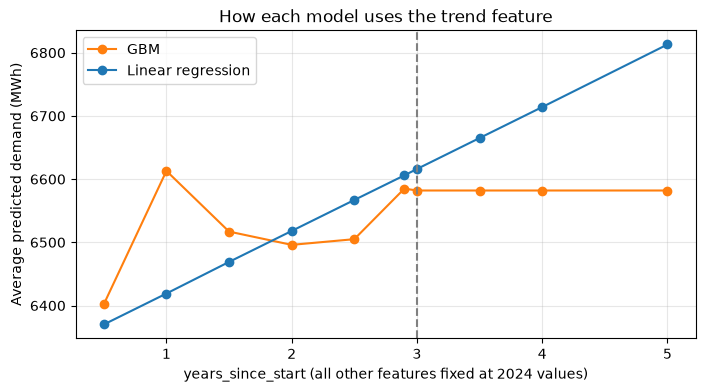

In [85]:
fig, ax = plt.subplots(figsize=(8, 4))

ax.plot(probe["years_since_start"], probe["avg_pred_gbm"], marker="o", color='C1', label="GBM")
ax.plot(probe["years_since_start"], probe["avg_pred_linear"], marker="o", color='C0', label="Linear regression")

ax.axvline(3.0, color="gray", linestyle="--") #max for training

ax.set_xlabel("years_since_start (all other features fixed at 2024 values)")
ax.set_ylabel("Average predicted demand (MWh)")
ax.set_title("How each model uses the trend feature")

ax.legend()
ax.grid(alpha=0.3)
plt.show()

The ending of the training does have a large impact on the GBM, at the 3 yrs mark and beyond the GBM flattens out so it predicts the same value for the years past training so 2024 and 2026 have same prediction, but this isn't seen in the linear trend where it keeps changing its demand. This explains why the bias grows since over time demand was growing but we no longer adjust for that so the BIAS should grow since predication is still using stagnant data. This is also showing the 'can't extrapolate' that was a guess of what was going on. The tree can only split values on what it has seen and its doesn't see anything beyond 3 for the trend. 

We can see that GBM does better of learning each yrs traits with the jump and dips at 1 to 2 yrs. 

Okay so how do we handle this... we can: 

| Option | HOW | PROS | CONS |
|---|---|---| --- |
| Do nothing | Retrain monthly so training data stays recent | Simple and common | Gap reopens between retrains, doesn't fix anything, have to remember |
| Add recent demand as feature| use demand from 48 hours ago | should track growth automatically | not exactly weather driven only anymore, have to account for something new |
| Remove trend before training | fit a straight line trend and train on demand minus this trend | The lines extrapolate and trees do what they normally do | trend is estimated, bad estimate gives bad results, growth may be accelerating which isn't a straight line |


In [86]:
#explore the options

#this is looking at removing the trend with a straight line

#a straight line through raw demand over time
raw_trend = LinearRegression().fit(X_train[["years_since_start"]], y_train) #get line fit
RAW_TREND = raw_trend.coef_[0]

#the linear regression's trend coefficient, which holds weather and calendar fixed
WEATHER_ADJ_TREND = lin.coef_[list(X_train_line.columns).index("years_since_start")]

print(f"raw trend: {RAW_TREND:.0f} MWh per year")
print(f"weather-adjusted trend: {WEATHER_ADJ_TREND:.0f} MWh per year")

raw trend: 58 MWh per year
weather-adjusted trend: 98 MWh per year


Raw takes the data as it is picking up weather so if demand drops but it is growing with time this will reduce it, hence the less MWh value. The Weather adjusted trand accounts for the weather and tries to measure the growth at the same weather so trying to see the underlying trend 

In [87]:
#train both
FEATURES_NO_TREND = [c for c in FEATURES if c != "years_since_start"]

def fit_detrended(trend_per_year, name):
    """
    Train GBM on demand minus a straight-line trend, then add the trend back.
    """

    y_detrended = y_train - trend_per_year * X_train["years_since_start"] # y =mx + b line where slope is trend and step is train take from the y_train values
    model = HistGradientBoostingRegressor(**BEST_PARAMS) #calls best GBM from before
    model.fit(X_train[FEATURES_NO_TREND], y_detrended) #fits on the detrended info
    pred = model.predict(X_valid[FEATURES_NO_TREND]) + trend_per_year * X_valid["years_since_start"].to_numpy()
    return model, pred

In [88]:
gbm_raw_trend, valid["pred_gbm_raw_trend"] = fit_detrended(RAW_TREND, "raw")
gbm_detrended, valid["pred_gbm_detrended"] = fit_detrended(WEATHER_ADJ_TREND, "weather-adjusted")

results.append(comparison(valid["demand_mwh"], valid["pred_gbm_raw_trend"], "GBM + raw trend"))
results.append(comparison(valid["demand_mwh"], valid["pred_gbm_detrended"], "GBM + weather-adjusted trend"))
pd.concat(results[-2:], ignore_index=True)

,model,mae_mwh,mape_pct,rmse_mwh,bias_mwh
0,GBM + raw trend,188.52,2.79,231.88,-151.01
1,GBM + weather-adjusted trend,145.68,2.14,190.88,-72.42


The weather adjusted does better and across the board and the RAW does comparable to just normal boosting

In [89]:
scores = pd.concat(results, ignore_index = True)
scores

,model,mae_mwh,mape_pct,rmse_mwh,bias_mwh
0,Same Hour last week,479.06,6.85,672.65,-7.26
1,Linear Regression,218.59,3.28,277.93,-59.80
2,EIA day-ahead 'Benchmark',134.68,1.97,178.53,-18.27
3,GBM default,198.54,2.88,252.82,-153.92
4,GBM (tuned),190.37,2.76,243.82,-142.66
5,GBM + raw trend,188.52,2.79,231.88,-151.01
6,GBM + weather-adjusted trend,145.68,2.14,190.88,-72.42


So EIA is still the best and the best we get is the GMB + weather adjusted trend which reduces the bia from GMB and also improves MAPE. The BIAS still being there and somewhat large indicates that maybe growth is accelerating or that a straight line detrending isn't the best estimate. We will use the LR detrended data for our model and note improvements could be made and this may be doing option 2 which is using the previous data to help inform the trend. 

This also leads to a guess of the test being even worse as we go further in time and the linear trend becomes worse. We could look at inclduing a bias correction term to features but we are looking at weather so going to forgo this for now. It would be worth coming back and use the validation year to choose which window would be best to correct for BIAS if needed. 

## Step 6 -> Test period (scored once)

In [90]:
#okay retrain including validation since we have our model and validation played its part in choosing
#going to do most models talked about strictly for comparison but our chosen model is GBM + weather adjusted trend
train_full = feat[feat["split"].isin(["train", "valid"])] #combine
test = feat[feat["split"] == "test"].reset_index(drop=True)

#full values 
X_full, y_full = train_full[FEATURES], train_full["demand_mwh"]
X_test, y_test = test[FEATURES], test["demand_mwh"]

#linear model on 2021-2024 baseline and the weather-adjusted trend
X_full_lin = pd.get_dummies(X_full, columns=CATEGORY, drop_first=True, dtype=int)
X_test_lin = pd.get_dummies(X_test, columns=CATEGORY, drop_first=True, dtype=int).reindex(columns=X_full_lin.columns, fill_value=0)

lin_final = LinearRegression().fit(X_full_lin, y_full)
TREND_FINAL = lin_final.coef_[list(X_full_lin.columns).index("years_since_start")]
print(f"weather-adjusted trend, 2021-2024: {TREND_FINAL:.0f} MWh per year")   

#GBM + weather-adjusted trend 
gbm_final = HistGradientBoostingRegressor(**BEST_PARAMS)
gbm_final.fit(X_full[FEATURES_NO_TREND], y_full - TREND_FINAL * X_full["years_since_start"])

#plain GBM, kept for comparison
gbm_plain_final = HistGradientBoostingRegressor(**BEST_PARAMS).fit(X_full, y_full)

#predictions for every test hour
test = test.merge(last_week, on="period_utc", how="left")
test["pred_last_week"] = test["demand_last_week"]
test["pred_linear"] = lin_final.predict(X_test_lin)
test["pred_gbm_plain"] = gbm_plain_final.predict(X_test)
test["pred_gbm"] = gbm_final.predict(X_test[FEATURES_NO_TREND]) + TREND_FINAL * X_test["years_since_start"].to_numpy()


weather-adjusted trend, 2021-2024: 117 MWh per year


In [91]:
# get the results/scores of the models
scored = test[test["eia_forecast_mwh"].notna()]

MODELS = {
    "EIA day-ahead (benchmark)": "eia_forecast_mwh",
    "GBM + weather-adjusted trend": "pred_gbm",
    "GBM (no trend fix)": "pred_gbm_plain",
    "Linear regression": "pred_linear",
    "Same hour last week": "pred_last_week",
}
test_results = pd.concat([
    comparison(scored["demand_mwh"], scored[col], name) for name, col in MODELS.items()
    ], 
    ignore_index=True)

test_results

,model,mae_mwh,mape_pct,rmse_mwh,bias_mwh
0,EIA day-ahead (benchmark),138.37,1.94,181.58,6.97
1,GBM + weather-adjusted trend,349.40,4.86,414.12,-337.86
2,GBM (no trend fix),380.41,5.23,465.20,-349.60
3,Linear regression,384.73,5.34,467.28,-346.43
4,Same hour last week,424.68,5.83,576.35,2.84


So the EIA still does better and we have gotten worse in all cases. This worsening was expected based on the bias seen in validation and noted so this points even more to an acceleration in growth or some shift that needs more than just a linear detrending. 

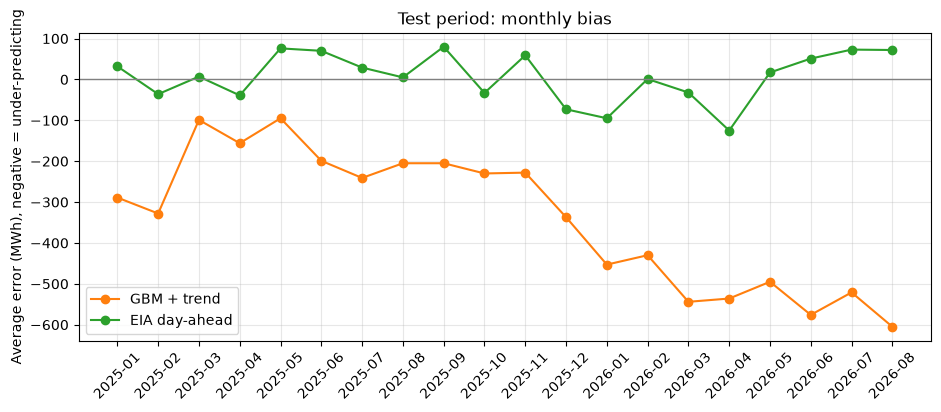

In [92]:
#bias by month across the 20-month test period
test_month = scored["period_utc"].dt.tz_convert("America/Los_Angeles").dt.strftime("%Y-%m") #get months

drift = pd.DataFrame({ #get drift of bias looking at difference between prediction and actual
    "GBM + trend": (scored["pred_gbm"] - scored["demand_mwh"]).groupby(test_month).mean(),
    "EIA": (scored["eia_forecast_mwh"] - scored["demand_mwh"]).groupby(test_month).mean(),
}).round(0)

#plot
fig, ax = plt.subplots(figsize=(11, 4))

ax.plot(drift.index, drift["GBM + trend"], marker="o", color="C1", label="GBM + trend")
ax.plot(drift.index, drift["EIA"], marker="o", color="C2", label="EIA day-ahead")

ax.axhline(0, color="gray", linewidth=1) #values were the same

ax.set_ylabel("Average error (MWh), negative = under-predicting")
ax.set_title("Test period: monthly bias")
ax.tick_params(axis="x", labelrotation=45)
ax.legend()

ax.grid(alpha=0.3)
plt.show()

**What the monthly bias shows:**
- EIA's bias stays within about ±125 MWh for all 20 months, with no trend.
- The model under-predicts every month, in two stages: about −100 to −330 MWh through most of 2025, then a step down around December 2025 to about −430 to −600 MWh for all of 2026.
- So the error isn't random month-to-month weather misses. Demand moved up to a new level, twice, and the model can't see it. That fits the Jan–Aug averages from notebook 03: about +275 MWh from 2024 to 2025, and about +320 more into 2026, far faster than the trend line.

### Where does the model miss?
for both forecasts on the test period: error by hour of day and by month.

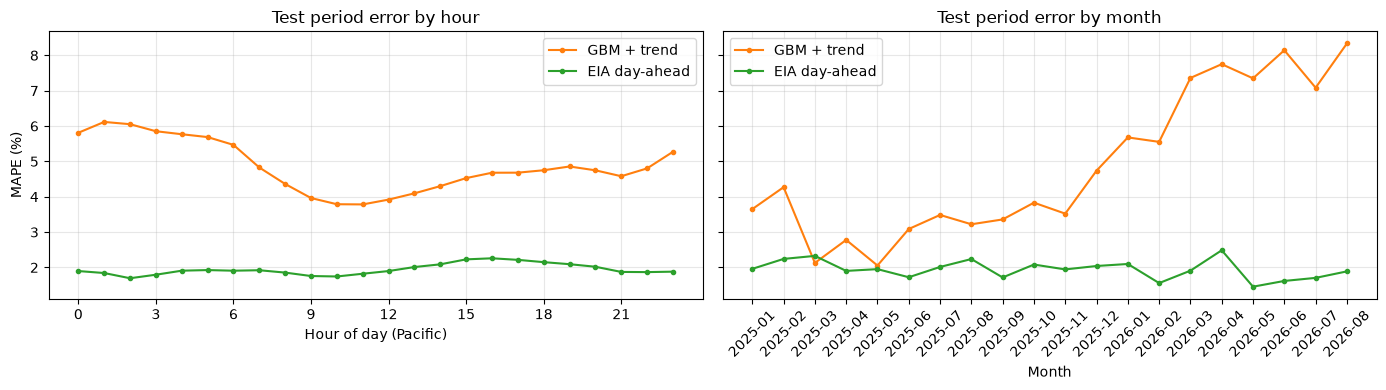

In [93]:
#absolute % error per hour for both forecasts
scored = scored.assign(
    ape_gbm=100 * (scored["pred_gbm"] - scored["demand_mwh"]).abs() / scored["demand_mwh"],
    ape_eia=100 * (scored["eia_forecast_mwh"] - scored["demand_mwh"]).abs() / scored["demand_mwh"],
)

by_hour = scored.groupby("hour_pacific")[["ape_gbm", "ape_eia"]].mean()
by_month = scored.groupby(test_month)[["ape_gbm", "ape_eia"]].mean()

fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)

axes[0].plot(by_hour.index, by_hour["ape_gbm"], marker="o", markersize=3, color="C1", label="GBM + trend")
axes[0].plot(by_hour.index, by_hour["ape_eia"], marker="o", markersize=3, color="C2", label="EIA day-ahead")
axes[0].set_xticks(range(0, 24, 3))
axes[0].set_xlabel("Hour of day (Pacific)")
axes[0].set_ylabel("MAPE (%)")
axes[0].set_title("Test period error by hour")

axes[1].plot(by_month.index, by_month["ape_gbm"], marker="o", markersize=3, color="C1", label="GBM + trend")
axes[1].plot(by_month.index, by_month["ape_eia"], marker="o", markersize=3, color="C2", label="EIA day-ahead")
axes[1].set_xlabel("Month")
axes[1].set_title("Test period error by month")
axes[1].tick_params(axis="x", labelrotation=45)

for ax in axes:
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**What it shows:**
- **By month:** the model is close to EIA in spring 2025 then jumps from December 2025 on. The same step as the bias chart and EIA stays the same throughout.
- **By hour:** the model is worst overnight and best late morning while EIA is flat by hour

The overnight pattern is a clue about what kind of load was added. 
Checking the bias in MWh by hour, the miss is roughly the same size at every hour. A constant block of extra load is a bigger percentage of demand at night, when total demand is lowest hence why we miss more there than the day. That points to new load that runs all the time rather than more heating or cooling. This data can't confirm the cause, but it narrows it down. 

In [94]:
#peak hours
peak_cutoff = scored["demand_mwh"].quantile(0.95) 
peaks = scored[scored["demand_mwh"] >= peak_cutoff]#look at top 5%
print(f"peak hours: demand >= {peak_cutoff:.0f} MWh ({len(peaks)} hours)")

pd.concat([
    comparison(peaks["demand_mwh"], peaks["eia_forecast_mwh"], "EIA day-ahead (peaks)"),
    comparison(peaks["demand_mwh"], peaks["pred_gbm"], "GBM + trend (peaks)"),
], ignore_index=True)

peak hours: demand >= 8794 MWh (729 hours)


,model,mae_mwh,mape_pct,rmse_mwh,bias_mwh
0,EIA day-ahead (peaks),176.16,1.90,227.56,-58.53
1,GBM + trend (peaks),465.63,5.02,532.42,-457.96


**Peak hours (top 5% of demand, ≥ 8,794 MWh, 729 hours):** EIA misses by 1.90% on average; the model by 5.02%, under-predicting by about 460 MWh. This is an important gap to close as can have large impacts

### Which features does the model rely on?

**Permutation importance:** shuffle one feature's values (breaking its link to demand), and measure how much worse the predictions get. A big increase in error means the model leans on that feature heavily. It's measured on the test period, but no decisions are made from it

In [95]:
#importance of each feature for the final model
y_test_detrended = y_test - TREND_FINAL * X_test["years_since_start"]

importance = permutation_importance(
    gbm_final, X_test[FEATURES_NO_TREND], y_test_detrended,
    scoring="neg_mean_absolute_error", n_repeats=5, random_state=42,
)

importance_df = (
    pd.DataFrame({"feature": FEATURES_NO_TREND,
                  "mae_increase_mwh": importance.importances_mean,
                  "std": importance.importances_std})
      .sort_values("mae_increase_mwh", ascending=False)
      .reset_index(drop=True)
)
importance_df.head(15)

,feature,mae_increase_mwh,std
0,hour_pacific,327.282738,2.450257
1,everett_temp_roll12_f,83.535918,0.341642
2,vancouver_wash_temp_roll12_f,61.421560,0.469927
3,kennewick_temp_f,54.515246,0.524401
4,kennewick_temp_roll12_f,54.222766,0.236989
5,month,45.593768,0.243799
6,day_of_week,44.258989,0.305741
7,kennewick_temp_roll24_f,40.695423,0.422878
8,eugene_temp_roll24_f,28.056896,0.393033
9,vancouver_wash_temp_f,26.873746,0.703767


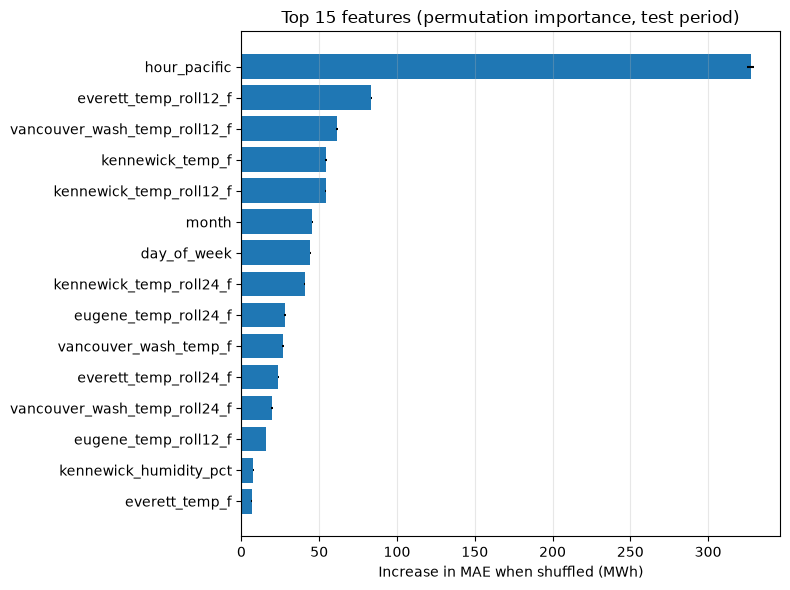

In [96]:
top = importance_df.head(15).iloc[::-1]   #reverse so the biggest bar is on top

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top["feature"], top["mae_increase_mwh"], xerr=top["std"], color="C0")
ax.set_xlabel("Increase in MAE when shuffled (MWh)")
ax.set_title("Top 15 features (permutation importance, test period)")
ax.grid(alpha=0.3, axis="x")
plt.tight_layout()
plt.show()

**What it shows:**
- **`hour_pacific` dominates** (shuffling it adds about 330 MWh of error): the daily cycle is the biggest single pattern in demand.
- **Recent weather beats current weather.** The 12-hour rolling temperatures for Everett, Vancouver WA and Kennewick are next, ahead of most current-hour temperatures. That confirms the notebook 03 finding 
- **Kennewick shows up three times** (current, 12 h and 24 h), consistent with it being the strongest heating signal in notebook 03.
- `month` and `day_of_week` matter (about 45 MWh each); humidity barely does, and wind, cloud and solar don't make the top 15.

We need to keep in mind:
- **Correlated features share credit.** The four locations' temperatures, rolling temperatures and degree-hours all carry similar information. Shuffling one barely hurts when its near-duplicates are still there, so each one looks less important than "temperature" is as a whole. That's likely why the degree-hour features don't appear: the trees can split on temperature directly, so degree-hours (built for the V shape) add little on top. They matter much more for the linear model.
- **Importance isn't accuracy.** These are the features the model relies on, but the model is still off by a growing amount, because none of these features can see the load growth.

### Save the test predictions
We will need these later.
`weather_source = 'actual'` marks them as best-case predictions, so they can be told apart from the forecasted weather later.

In [97]:
#need to go from pandas to SQL
#use register and then create
con.register("test_preds", test[["period_utc", "demand_mwh", "eia_forecast_mwh",
                                 "pred_gbm", "pred_gbm_plain", "pred_linear", "pred_last_week"]])
con.sql("""
    CREATE OR REPLACE TABLE predictions_test AS
    SELECT *, 'actual' AS weather_source
    FROM test_preds
    ORDER BY period_utc
""")

#quick check
con.sql("""
    SELECT COUNT(*) AS n_hours, MIN(period_utc) AS first_hour, MAX(period_utc) AS last_hour
    FROM predictions_test
""")

┌─────────┬──────────────────────────┬──────────────────────────┐
│ n_hours │        first_hour        │        last_hour         │
│  int64  │ timestamp with time zone │ timestamp with time zone │
├─────────┼──────────────────────────┼──────────────────────────┤
│   14584 │ 2025-01-01 08:00:00+00   │ 2026-08-31 23:00:00+00   │
└─────────┴──────────────────────────┴──────────────────────────┘

Got 14,584 hours, matching the test split. Every test hour is saved (including the 24 with no EIA forecast), so later notebooks can apply the same "score only where both exist" rule themselves.

## Summary

**Validation (2024), choosing the model:**

| model | MAPE (%) | bias (MWh) |
|---|---|---|
| EIA day-ahead (benchmark) | 1.97 | −18 |
| **GBM + weather-adjusted trend** | **2.14** | −72 |
| GBM (tuned) | 2.76 | −143 |
| Linear regression | 3.28 | −60 |
| Same hour last week | 6.85 | −7 |

**Test (Jan 2025 – Aug 2026), scored once:**

| model | MAPE (%) | bias (MWh) |
|---|---|---|
| EIA day-ahead (benchmark) | 1.94 | +7 |
| **GBM + weather-adjusted trend** | **4.86** | −338 |
| GBM (no trend fix) | 5.23 | −350 |
| Linear regression | 5.34 | −346 |
| Same hour last week | 5.83 | +3 |

**Findings:**
1. **Gradient boosting beats both baselines** and, on validation, came within 0.17 points of EIA.
2. **Trees can't extrapolate a trend.** The probe showed the GBM freezing at the last training level. Removing a *weather-adjusted* trend first (from the linear model) fixed most of it on validation (2.76% → 2.14%), while a raw trend didn't help.
3. **The test period broke the model.** Demand stepped up faster than any trend from 2021–2024 could predict (twice, the second step around December 2025), as a roughly constant block of load at every hour. Error rose from ~3–4% in 2025 to 5–8% in 2026, and the model misses peak hours by about 460 MWh.
4. **What the model relies on:** hour of day, then recent (12 h) temperatures, especially Kennewick's.

**Limitations:**
- **Best case only:** the model used *actual* weather
- **Weather alone can't anticipate new load.** 

**Next:**
- **include bias correction to account for growth:** a recent-error correction, using the model's own error over a recent window. The window gets chosen on the validation year, then the test period is scored once more.
- **Round 2:** score the model with day-ahead forecasted weather 
- **Notebook 05:** a Bayesian model that can estimate the level shift with uncertainty.

In [98]:
#release the database so other notebooks and load_data.py can open it
con.close()